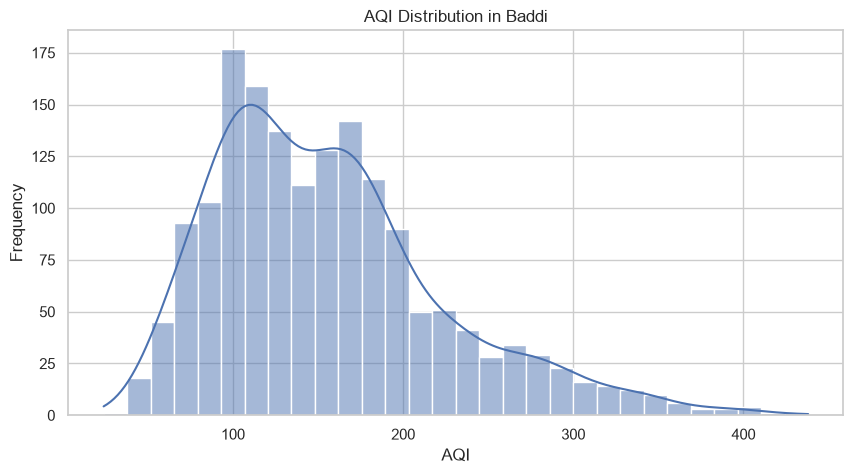

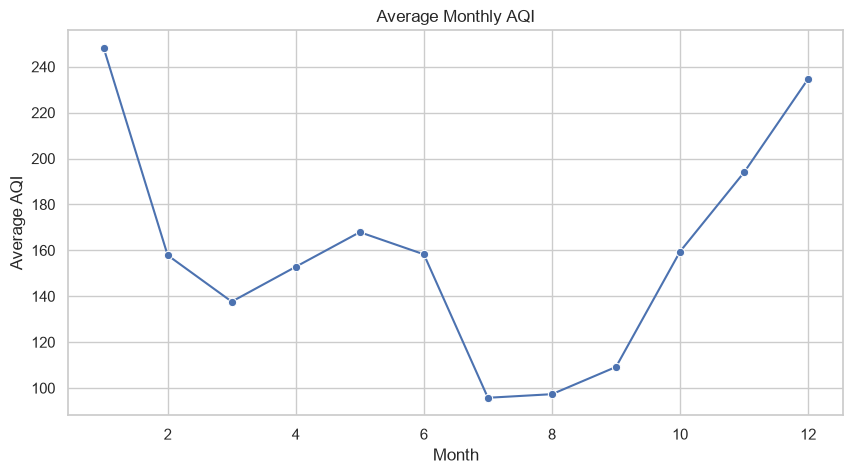

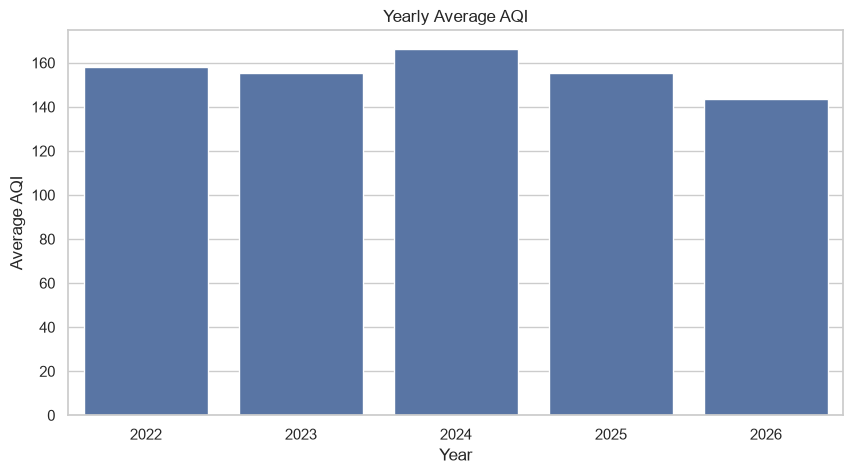

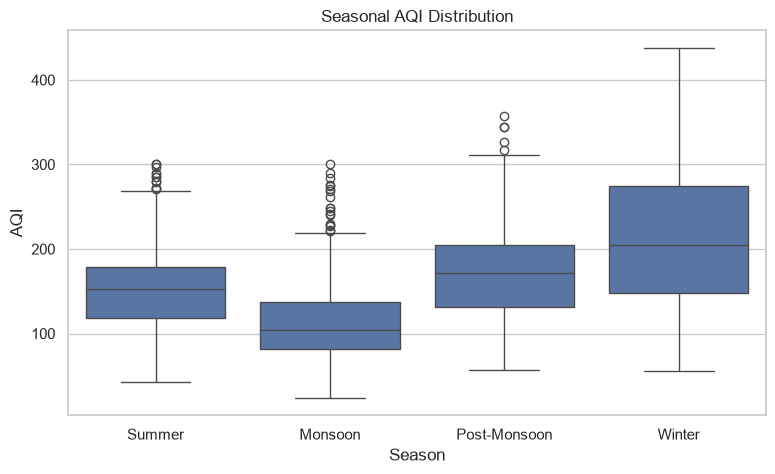

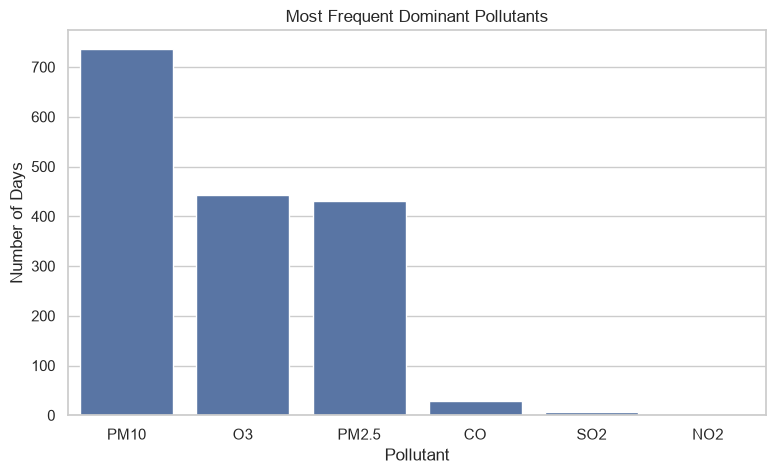

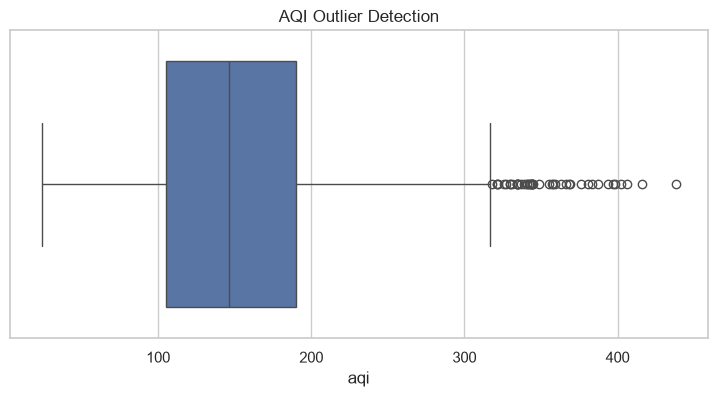

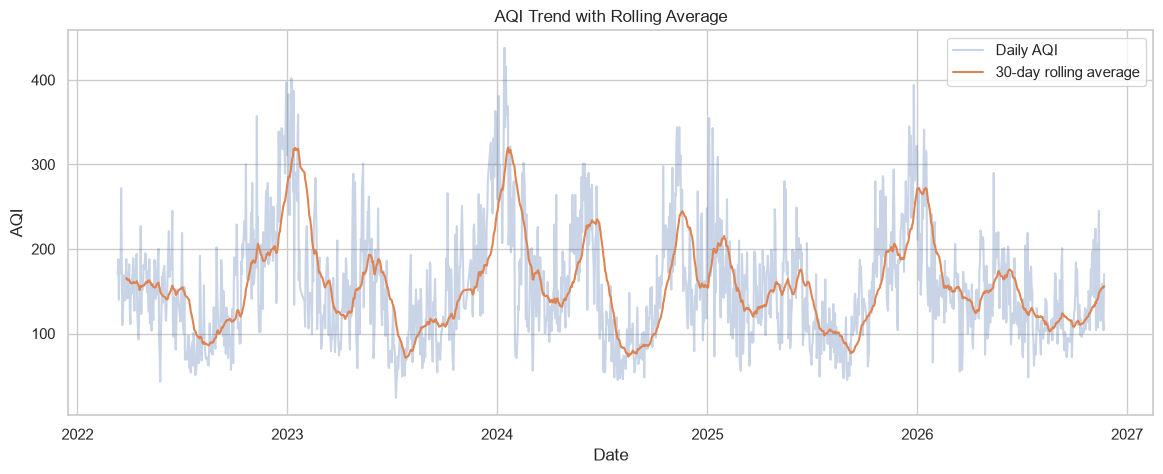


========== EDA SUMMARY ==========

Average AQI: 155.97080291970804

Highest AQI: 438

Lowest AQI: 24

Dominant Pollutants:
main_pollutant
PM10     737
O3       442
PM2.5    430
CO        28
SO2        6
NO2        1
Name: count, dtype: int64

Seasonal Average AQI:
season
Monsoon         114.696763
Post-Monsoon    175.621429
Summer          152.935484
Winter          214.405248
Name: aqi, dtype: float64

EDA COMPLETED!


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load cleaned dataset
df = pd.read_csv("data/cleaned_baddi_aqi.csv")

df["date"] = pd.to_datetime(df["date"])

os.makedirs("visualizations", exist_ok=True)

sns.set_theme(style="whitegrid")

# --------------------------------
# 1. AQI Distribution
# --------------------------------

plt.figure(figsize=(10, 5))

sns.histplot(df["aqi"], bins=30, kde=True)

plt.title("AQI Distribution in Baddi")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.savefig("visualizations/aqi_distribution.png")
plt.show()


# --------------------------------
# 2. Monthly AQI Trend
# --------------------------------

monthly = df.groupby("month")["aqi"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(x=monthly.index, y=monthly.values, marker="o")

plt.title("Average Monthly AQI")
plt.xlabel("Month")
plt.ylabel("Average AQI")

plt.savefig("visualizations/monthly_trend.png")
plt.show()


# --------------------------------
# 3. Yearly AQI Trend
# --------------------------------

yearly = df.groupby("year")["aqi"].mean()

plt.figure(figsize=(10, 5))

sns.barplot(x=yearly.index, y=yearly.values)

plt.title("Yearly Average AQI")
plt.xlabel("Year")
plt.ylabel("Average AQI")

plt.savefig("visualizations/yearly_trend.png")
plt.show()


# --------------------------------
# 4. Seasonal Pollution
# --------------------------------

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="season", y="aqi")

plt.title("Seasonal AQI Distribution")
plt.xlabel("Season")
plt.ylabel("AQI")

plt.savefig("visualizations/seasonal_aqi.png")
plt.show()


# --------------------------------
# 5. Dominant Pollutants
# --------------------------------

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="main_pollutant",
    order=df["main_pollutant"].value_counts().index
)

plt.title("Most Frequent Dominant Pollutants")
plt.xlabel("Pollutant")
plt.ylabel("Number of Days")

plt.savefig("visualizations/dominant_pollutants.png")
plt.show()


# --------------------------------
# 6. AQI Outlier Detection
# --------------------------------

plt.figure(figsize=(9, 4))

sns.boxplot(x=df["aqi"])

plt.title("AQI Outlier Detection")

plt.savefig("visualizations/aqi_outliers.png")
plt.show()


# --------------------------------
# 7. Rolling Average
# --------------------------------

df = df.sort_values("date")

df["rolling_30"] = df["aqi"].rolling(
    window=30,
    min_periods=15
).mean()

plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["aqi"], alpha=0.3, label="Daily AQI")

plt.plot(
    df["date"],
    df["rolling_30"],
    label="30-day rolling average"
)

plt.title("AQI Trend with Rolling Average")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.savefig("visualizations/rolling_average.png")
plt.show()


print("\n========== EDA SUMMARY ==========")

print("\nAverage AQI:", df["aqi"].mean())

print("\nHighest AQI:", df["aqi"].max())

print("\nLowest AQI:", df["aqi"].min())

print("\nDominant Pollutants:")
print(df["main_pollutant"].value_counts())

print("\nSeasonal Average AQI:")
print(df.groupby("season")["aqi"].mean())

print("\nEDA COMPLETED!")